# Day 7 — Order ID, Quantity, Discount and Returns Analysis

## Project
Sales Business Performance Analytics Dashboard

## Objective
Analyze order identifiers, product quantities, discount patterns, and returned orders using the cleaned Superstore dataset and the original workbook's Returns sheet.

## Scope and data grain
- **Orders dataset:** order-item level. Each row represents a product line within an order.
- **Order-level metrics:** calculated using distinct `Order ID` values.
- **Returns dataset:** order-level. Each returned order is identified by `Order ID`.
- Raw source files are read-only and are not modified.

## Questions
1. How many unique orders and order items are present?
2. How many items are associated with each order?
3. What does the quantity distribution look like?
4. How are discounts distributed, and how do sales and profit vary by discount?
5. How many orders were returned, and what is the return rate?


## 1. Import libraries and load datasets

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
CLEANED_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_superstore.csv"
RAW_WORKBOOK_PATH = PROJECT_ROOT / "data" / "raw" / "sample_-_superstore.xls"

assert CLEANED_PATH.exists(), f"Cleaned dataset not found: {CLEANED_PATH}"
assert RAW_WORKBOOK_PATH.exists(), f"Raw workbook not found: {RAW_WORKBOOK_PATH}"

orders = pd.read_csv(CLEANED_PATH, dtype={"Postal Code": "string"})
returns = pd.read_excel(RAW_WORKBOOK_PATH, sheet_name="Returns")

print("Orders dataset shape:", orders.shape)
print("Returns dataset shape:", returns.shape)
print("\nOrders columns:")
print(orders.columns.tolist())
print("\nReturns columns:")
print(returns.columns.tolist())


Orders dataset shape: (10194, 21)
Returns dataset shape: (296, 2)

Orders columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Returns columns:
['Order ID', 'Returned']


## 2. Initial data validation

In [2]:
required_order_columns = {
    "Row ID", "Order ID", "Quantity", "Discount", "Sales", "Profit"
}
required_return_columns = {"Order ID", "Returned"}

assert required_order_columns.issubset(orders.columns)
assert required_return_columns.issubset(returns.columns)

overview = pd.DataFrame({
    "Metric": [
        "Order-item rows",
        "Unique orders",
        "Unique Row IDs",
        "Duplicate complete rows",
        "Missing Order IDs",
        "Returns records",
        "Missing return Order IDs",
        "Duplicate return Order IDs"
    ],
    "Value": [
        len(orders),
        orders["Order ID"].nunique(),
        orders["Row ID"].nunique(),
        orders.duplicated().sum(),
        orders["Order ID"].isna().sum(),
        len(returns),
        returns["Order ID"].isna().sum(),
        returns["Order ID"].duplicated().sum()
    ]
})

display(overview)


,Metric,Value
0,Order-item rows,10194
1,Unique orders,5111
2,Unique Row IDs,10194
3,Duplicate complete rows,0
4,Missing Order IDs,0
5,Returns records,296
6,Missing return Order IDs,0
7,Duplicate return Order IDs,0


## 3. Order ID analysis

Order counts must use distinct `Order ID` values. The number of rows in the Orders dataset represents order items, not unique orders.

Order-item rows: 10194
Unique orders: 5111
Single-item orders: 2593
Multi-item orders: 2518
Maximum items in one order: 14


,Items per Order
count,5111.00
mean,1.99
std,1.41
min,1.00
25%,1.00
50%,1.00
75%,2.00
max,14.00


,Items per Order,Number of Orders
0,1,2593
1,2,1242
2,3,612
3,4,344
4,5,164
5,6,72
6,7,51
7,8,16
8,9,10
9,10,3


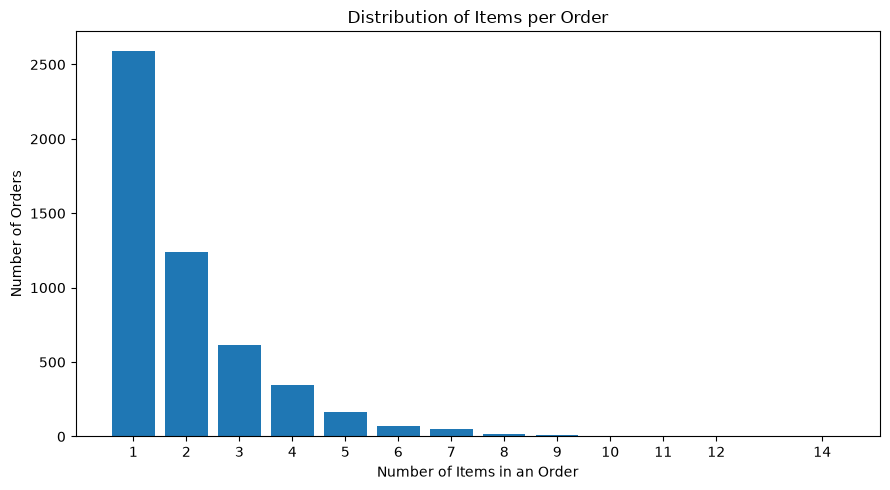

In [3]:
order_item_counts = orders.groupby("Order ID").size().rename("Order Items")

order_summary = order_item_counts.describe().to_frame("Items per Order")
single_item_orders = int((order_item_counts == 1).sum())
multi_item_orders = int((order_item_counts > 1).sum())

print("Order-item rows:", len(orders))
print("Unique orders:", orders["Order ID"].nunique())
print("Single-item orders:", single_item_orders)
print("Multi-item orders:", multi_item_orders)
print("Maximum items in one order:", int(order_item_counts.max()))

display(order_summary.round(2))

items_distribution = (
    order_item_counts.value_counts()
    .sort_index()
    .rename_axis("Items per Order")
    .reset_index(name="Number of Orders")
)
display(items_distribution)

plt.figure(figsize=(9, 5))
plt.bar(items_distribution["Items per Order"], items_distribution["Number of Orders"])
plt.title("Distribution of Items per Order")
plt.xlabel("Number of Items in an Order")
plt.ylabel("Number of Orders")
plt.xticks(items_distribution["Items per Order"])
plt.tight_layout()
plt.show()


## 4. Quantity analysis

Total units sold: 38654
Zero-quantity rows: 0
Negative-quantity rows: 0


,Quantity
count,10194.00
mean,3.79
std,2.23
min,1.00
25%,2.00
50%,3.00
75%,5.00
max,14.00


,Quantity,Order Items
0,1,933
1,2,2440
2,3,2435
3,4,1212
4,5,1269
5,6,585
6,7,617
7,8,269
8,9,259
9,10,61


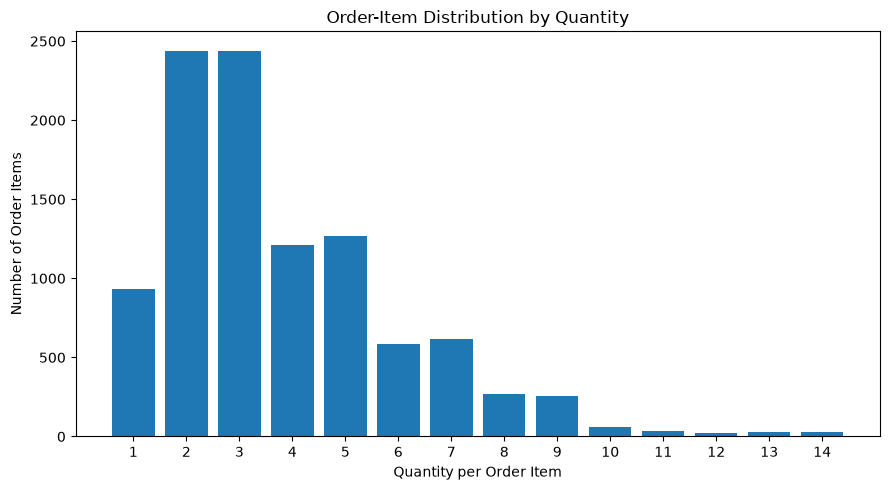

In [4]:
quantity_summary = orders["Quantity"].describe().to_frame("Quantity")
quantity_distribution = (
    orders["Quantity"].value_counts()
    .sort_index()
    .rename_axis("Quantity")
    .reset_index(name="Order Items")
)

total_quantity = int(orders["Quantity"].sum())
zero_quantities = int((orders["Quantity"] == 0).sum())
negative_quantities = int((orders["Quantity"] < 0).sum())

print("Total units sold:", total_quantity)
print("Zero-quantity rows:", zero_quantities)
print("Negative-quantity rows:", negative_quantities)
display(quantity_summary.round(2))
display(quantity_distribution)

plt.figure(figsize=(9, 5))
plt.bar(quantity_distribution["Quantity"], quantity_distribution["Order Items"])
plt.title("Order-Item Distribution by Quantity")
plt.xlabel("Quantity per Order Item")
plt.ylabel("Number of Order Items")
plt.xticks(quantity_distribution["Quantity"])
plt.tight_layout()
plt.show()


## 5. Discount analysis

Discount is analyzed at the order-item level. Sales and profit are aggregated for each discount value. These are descriptive relationships and do not establish that discounts alone cause changes in profit.

Discounted order items: 5269
Order items without discount: 4925
Percentage of discounted order items: 51.69 %
Average discount: 0.1554


,Discount,Order_Items,Sales,Profit,Quantity,Average_Sales,Average_Profit
0,0.00,4925,1105323.79,326718.59,18770,224.43,66.34
1,0.10,96,54952.50,9099.97,377,572.42,94.79
2,0.15,52,27558.52,1418.99,198,529.97,27.29
3,0.20,3706,773939.40,91079.95,13856,208.83,24.58
4,0.30,230,104474.07,-10513.45,855,454.24,-45.71
5,0.32,27,14493.46,-2391.14,105,536.79,-88.56
6,0.40,207,116497.76,-23086.37,789,562.79,-111.53
7,0.45,11,5484.97,-2493.11,45,498.63,-226.65
8,0.50,66,58918.54,-20506.43,241,892.71,-310.70
9,0.60,149,7105.94,-6164.35,554,47.69,-41.37


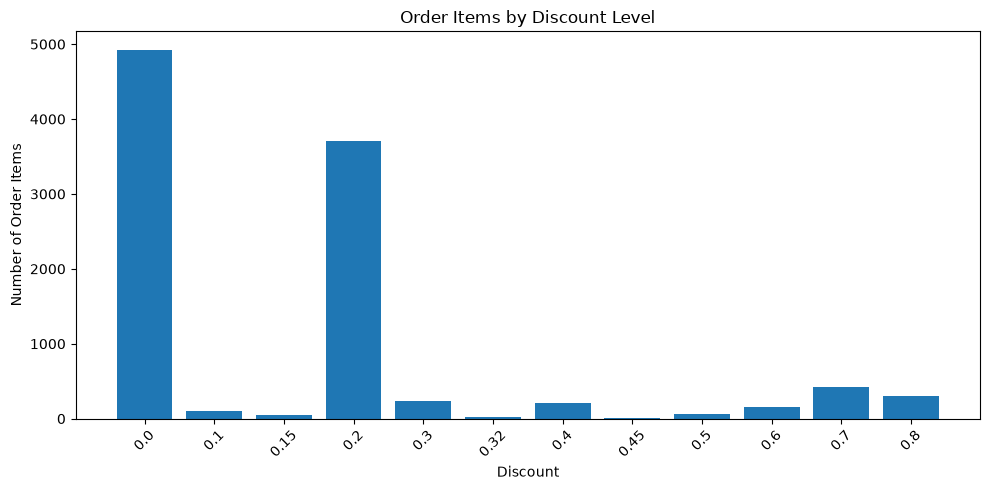

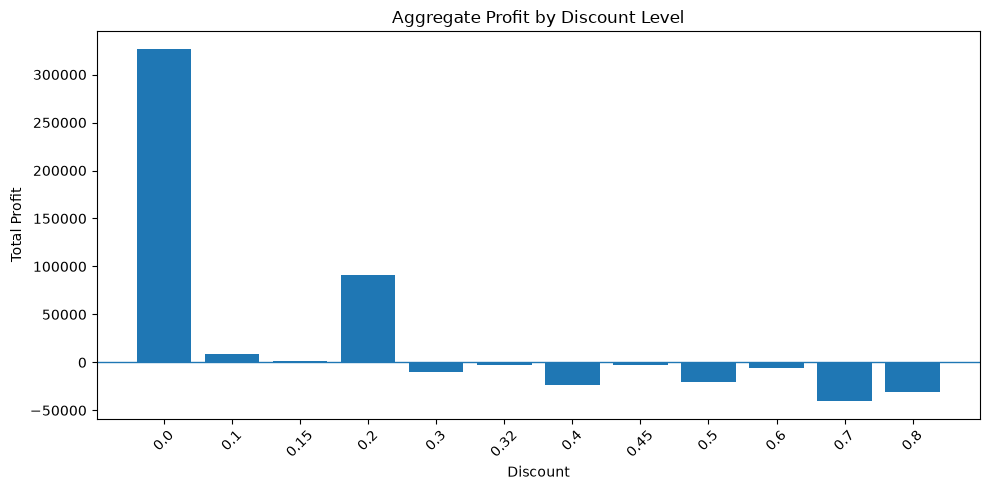

In [5]:
discount_summary = (
    orders.groupby("Discount", dropna=False)
    .agg(
        Order_Items=("Row ID", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Profit=("Profit", "mean")
    )
    .reset_index()
    .sort_values("Discount")
)

discounted_items = int((orders["Discount"] > 0).sum())
no_discount_items = int((orders["Discount"] == 0).sum())
discounted_percentage = discounted_items / len(orders) * 100

print("Discounted order items:", discounted_items)
print("Order items without discount:", no_discount_items)
print("Percentage of discounted order items:", round(discounted_percentage, 2), "%")
print("Average discount:", round(orders["Discount"].mean(), 4))
display(discount_summary.round(2))

plt.figure(figsize=(10, 5))
plt.bar(
    discount_summary["Discount"].astype(str),
    discount_summary["Order_Items"]
)
plt.title("Order Items by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Number of Order Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(
    discount_summary["Discount"].astype(str),
    discount_summary["Profit"]
)
plt.axhline(0, linewidth=1)
plt.title("Aggregate Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Returns analysis

The Returns sheet is matched to the cleaned Orders dataset using `Order ID`. The return rate uses unique orders as its denominator, not order-item rows.

In [6]:
order_ids = set(orders["Order ID"].dropna().astype(str))
return_ids = set(returns["Order ID"].dropna().astype(str))

matched_return_ids = return_ids & order_ids
unmatched_return_ids = return_ids - order_ids

returned_orders = len(return_ids)
total_orders = orders["Order ID"].nunique()
non_returned_orders = total_orders - returned_orders
return_rate = returned_orders / total_orders * 100

print("Returns records:", len(returns))
print("Unique returned Order IDs:", returns["Order ID"].nunique())
print("Matched returned Order IDs:", len(matched_return_ids))
print("Unmatched returned Order IDs:", len(unmatched_return_ids))
print("Returned status values:")
display(returns["Returned"].value_counts(dropna=False).to_frame("Records"))

print("\nTotal unique orders:", total_orders)
print("Returned orders:", returned_orders)
print("Orders without a return record:", non_returned_orders)
print("Return rate:", round(return_rate, 2), "%")

assert len(unmatched_return_ids) == 0, "Some return IDs do not match the Orders dataset."
assert returns["Order ID"].isna().sum() == 0
assert returns["Order ID"].duplicated().sum() == 0


Returns records: 296
Unique returned Order IDs: 296
Matched returned Order IDs: 296
Unmatched returned Order IDs: 0
Returned status values:


,Records
Returned,
Yes,296



Total unique orders: 5111
Returned orders: 296
Orders without a return record: 4815
Return rate: 5.79 %


## 7. Consolidated KPI summary

In [7]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total unique orders",
        "Total order items",
        "Total units sold",
        "Single-item orders",
        "Multi-item orders",
        "Discounted order items",
        "Discounted order-item percentage",
        "Returned orders",
        "Orders without a return record",
        "Return rate"
    ],
    "Value": [
        total_orders,
        len(orders),
        total_quantity,
        single_item_orders,
        multi_item_orders,
        discounted_items,
        round(discounted_percentage, 2),
        returned_orders,
        non_returned_orders,
        round(return_rate, 2)
    ],
    "Unit": [
        "Orders", "Order items", "Units", "Orders", "Orders",
        "Order items", "%", "Orders", "Orders", "%"
    ]
})

display(kpi_summary)


,KPI,Value,Unit
0,Total unique orders,5111.00,Orders
1,Total order items,10194.00,Order items
2,Total units sold,38654.00,Units
3,Single-item orders,2593.00,Orders
4,Multi-item orders,2518.00,Orders
5,Discounted order items,5269.00,Order items
6,Discounted order-item percentage,51.69,%
7,Returned orders,296.00,Orders
8,Orders without a return record,4815.00,Orders
9,Return rate,5.79,%


## 8. Final validation checks

In [8]:
validation_checks = {
    "Expected order-item row count": len(orders) == 10194,
    "Expected unique order count": total_orders == 5111,
    "No duplicate Row IDs": orders["Row ID"].duplicated().sum() == 0,
    "No duplicate complete rows": orders.duplicated().sum() == 0,
    "All quantities are positive": (orders["Quantity"] > 0).all(),
    "No missing Order IDs": orders["Order ID"].isna().sum() == 0,
    "Returns contain 296 records": len(returns) == 296,
    "Returns have unique Order IDs": returns["Order ID"].duplicated().sum() == 0,
    "All return IDs match Orders": len(unmatched_return_ids) == 0,
    "Returned status is Yes": returns["Returned"].eq("Yes").all()
}

validation_results = pd.DataFrame({
    "Validation": list(validation_checks.keys()),
    "Passed": list(validation_checks.values())
})

display(validation_results)
assert all(validation_checks.values()), "One or more Day 7 validation checks failed."

print("Day 7 validation: PASSED")


,Validation,Passed
0,Expected order-item row count,True
1,Expected unique order count,True
2,No duplicate Row IDs,True
3,No duplicate complete rows,True
4,All quantities are positive,True
5,No missing Order IDs,True
6,Returns contain 296 records,True
7,Returns have unique Order IDs,True
8,All return IDs match Orders,True
9,Returned status is Yes,True


Day 7 validation: PASSED


## 9. Findings and interpretation

- Order-level metrics use distinct Order IDs, while quantity and discount analyses use order-item rows.
- The order-item dataset contains both single-item and multi-item orders.
- Quantity values are checked for zero and negative entries before interpretation.
- Discount levels are compared with aggregate sales and profit. Negative aggregate profit at a discount level is an observed association, not proof of causation.
- Returns are validated by matching returned Order IDs against unique Order IDs in the cleaned Orders dataset.
- Return rate is calculated as returned unique orders divided by total unique orders.

## Completion

This notebook provides reproducible Day 7 analysis. The accompanying Markdown report records the verified findings and methodological limitations.
